NAME: SRI DURGA VARSINI P
THE UNLOX ACADEMY


PROJECT - Supervised ML Classification Project - Project Spec & Data Dictionary

# Title - **QuickCart Warehouse Inventory Stockout Risk**

In [ ]:
import os

print("Files available in Colab:")
print(os.listdir('/content'))

Files available in Colab:
['.config', 'dim_stores.csv', 'dim_skus.csv', 'fact_inventory_daily.csv', 'dim_events.csv', 'dim_suppliers.csv', 'sample_data']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

stores = pd.read_csv('/content/dim_stores.csv')
skus = pd.read_csv('/content/dim_skus.csv')
suppliers = pd.read_csv(
    '/content/dim_suppliers.csv',
    na_values=['N/A', 'missing', '--', 'NA', 'null']
)
events = pd.read_csv('/content/dim_events.csv')
inventory = pd.read_csv('/content/fact_inventory_daily.csv')
print("Stores:", stores.shape)
print("SKUs:", skus.shape)
print("Suppliers:", suppliers.shape)
print("Events:", events.shape)
print("Inventory:", inventory.shape)

stores.head()

Stores: (12, 8)
SKUs: (60, 9)
Suppliers: (15, 6)
Events: (30, 5)
Inventory: (21600, 16)


,store_id,city,city_display,city_tier,store_size,sqft,opened_year,baseline_daily_orders
0,ST01,Mumbai,Mumbai,Tier1,Large,2946,2023,580
1,ST02,Mumbai,Mumbai,Tier1,Small,1482,2024,235
2,ST03,Bengaluru,BENGALURU,Tier1,Large,3650,2022,552
3,ST04,Bengaluru,Bengaluru,Tier1,Large,4198,2025,524
4,ST05,Delhi,Delhi,Tier1,Medium,2220,2022,343


In [ ]:
inventory.head()

,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,lead_time_days_expected,lead_time_days_actual,sales_velocity_7d,days_of_cover,is_festival_week,stockout_risk
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,1,NaN,15.00,9.66,N,Safe
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,1,NaN,12.50,10.79,N,Safe
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,1,NaN,13.33,8.99,N,Safe
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,1,NaN,12.50,8.79,N,Safe
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,1,NaN,11.80,8.55,N,Safe


In [ ]:
print("STORES COLUMNS:")
print(stores.columns.tolist())

print("\nSKUS COLUMNS:")
print(skus.columns.tolist())

print("\nSUPPLIERS COLUMNS:")
print(suppliers.columns.tolist())

print("\nEVENTS COLUMNS:")
print(events.columns.tolist())

print("\nINVENTORY COLUMNS:")
print(inventory.columns.tolist())

STORES COLUMNS:
['store_id', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders']

SKUS COLUMNS:
['sku_id', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_id']

SUPPLIERS COLUMNS:
['supplier_id', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days']

EVENTS COLUMNS:
['date', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other']

INVENTORY COLUMNS:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']


In [ ]:
datasets = {
    "Stores": stores,
    "SKUs": skus,
    "Suppliers": suppliers,
    "Events": events,
    "Inventory": inventory
}

for name, df in datasets.items():
    print("\n" + "="*50)
    print(name)
    print("="*50)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())


Stores

Data Types:
store_id                 object
city                     object
city_display             object
city_tier                object
store_size               object
sqft                      int64
opened_year               int64
baseline_daily_orders     int64
dtype: object

Missing Values:
store_id                 0
city                     0
city_display             0
city_tier                0
store_size               0
sqft                     0
opened_year              0
baseline_daily_orders    0
dtype: int64

SKUs

Data Types:
sku_id               object
sku_name             object
category             object
unit_price_inr      float64
shelf_life_days       int64
is_perishable        object
festive_relevant     object
popularity_tier      object
supplier_id          object
dtype: object

Missing Values:
sku_id              0
sku_name            0
category            0
unit_price_inr      0
shelf_life_days     0
is_perishable       0
festive_relevant    0
popular

In [ ]:
import os

print(os.listdir('/content'))

['.config', 'dim_stores.csv', 'dim_skus.csv', 'dim_suppliers.csv', 'fact_inventory_daily.csv', 'dim_events.csv', 'sample_data']


In [ ]:
import pandas as pd

# Load all datasets
stores = pd.read_csv('/content/dim_stores.csv')

skus = pd.read_csv('/content/dim_skus.csv')

suppliers = pd.read_csv(
    '/content/dim_suppliers.csv',
    na_values=['N/A', 'missing', '--', 'NA', 'null']
)

events = pd.read_csv('/content/dim_events.csv')

inventory = pd.read_csv('/content/fact_inventory_daily.csv')

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [ ]:
# Start with the main inventory dataset
df = inventory.copy()

# Merge store information
df = df.merge(
    stores,
    on='store_id',
    how='left'
)

# Merge SKU information
df = df.merge(
    skus,
    on=['sku_id', 'supplier_id'],
    how='left'
)

# Merge supplier information
df = df.merge(
    suppliers,
    on='supplier_id',
    how='left'
)

# Merge event information
df = df.merge(
    events,
    on='date',
    how='left'
)

print("Merged dataset shape:", df.shape)
display(df.head())

Merged dataset shape: (21600, 39)


,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,...,popularity_tier,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days,event_name,event_type,demand_multiplier_festive,demand_multiplier_other
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,...,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,...,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,...,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,...,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,...,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0


In [ ]:
print(df.shape)
print(df.isnull().sum())

(21600, 39)
date                             0
store_id                         0
sku_id                           0
supplier_id                      0
opening_stock                    0
units_demanded                   0
units_sold                       0
closing_stock                    0
reorder_point                    0
reorder_placed                   0
lead_time_days_expected          0
lead_time_days_actual        19899
sales_velocity_7d                0
days_of_cover                    0
is_festival_week                 0
stockout_risk                    0
city                             0
city_display                     0
city_tier                        0
store_size                       0
sqft                             0
opened_year                      0
baseline_daily_orders            0
sku_name                         0
category                         0
unit_price_inr                   0
shelf_life_days                  0
is_perishable                    0
festive_

In [13]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (21600, 39)

Missing Values:
date                             0
store_id                         0
sku_id                           0
supplier_id                      0
opening_stock                    0
units_demanded                   0
units_sold                       0
closing_stock                    0
reorder_point                    0
reorder_placed                   0
lead_time_days_expected          0
lead_time_days_actual        19899
sales_velocity_7d                0
days_of_cover                    0
is_festival_week                 0
stockout_risk                    0
city                             0
city_display                     0
city_tier                        0
store_size                       0
sqft                             0
opened_year                      0
baseline_daily_orders            0
sku_name                         0
category                         0
unit_price_inr                   0
shelf_life_days                  0
is_perishab

In [16]:
# Fill missing reliability scores with the median
df['reliability_score'] = df['reliability_score'].fillna(
    df['reliability_score'].median()
)

print("Missing reliability scores:")
print(df['reliability_score'].isnull().sum())



Missing reliability scores:
0


In [17]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [18]:
print(df['stockout_risk'].value_counts())

print("\nPercentage distribution:")
print(df['stockout_risk'].value_counts(normalize=True) * 100)

stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

Percentage distribution:
stockout_risk
Safe        65.421296
At-Risk     24.009259
Imminent    10.569444
Name: proportion, dtype: float64


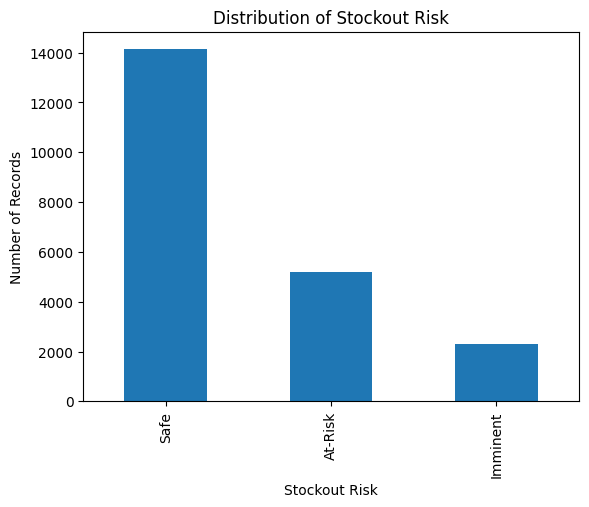

In [19]:
import matplotlib.pyplot as plt

df['stockout_risk'].value_counts().plot(
    kind='bar'
)

plt.title('Distribution of Stockout Risk')
plt.xlabel('Stockout Risk')
plt.ylabel('Number of Records')
plt.show()

In [20]:
df.shape
df['stockout_risk'].value_counts()

,count
stockout_risk,
Safe,14131
At-Risk,5186
Imminent,2283


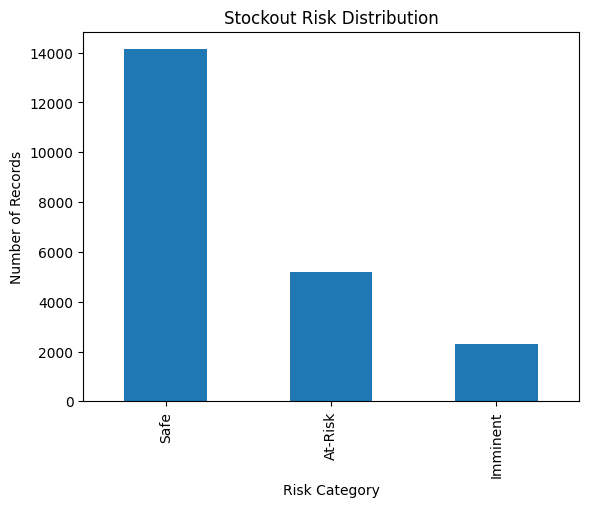

In [21]:
import matplotlib.pyplot as plt

df['stockout_risk'].value_counts().plot(kind='bar')

plt.title('Stockout Risk Distribution')
plt.xlabel('Risk Category')
plt.ylabel('Number of Records')
plt.show()

In [22]:
festival_analysis = pd.crosstab(
    df['is_festival_week'],
    df['stockout_risk'],
    normalize='index'
) * 100

print(festival_analysis)

stockout_risk       At-Risk   Imminent       Safe
is_festival_week                                 
N                 24.192740   9.511633  66.295628
Y                 21.799517  23.309179  54.891304


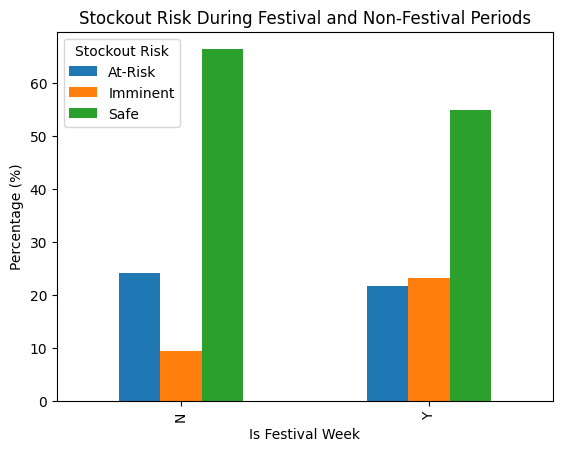

In [23]:
festival_analysis.plot(kind='bar')

plt.title('Stockout Risk During Festival and Non-Festival Periods')
plt.xlabel('Is Festival Week')
plt.ylabel('Percentage (%)')
plt.legend(title='Stockout Risk')
plt.show()

In [24]:
def reliability_group(score):
    if score < 0.75:
        return 'Low'
    elif score < 0.85:
        return 'Medium'
    else:
        return 'High'

df['reliability_group'] = df['reliability_score'].apply(reliability_group)

In [25]:
supplier_analysis = pd.crosstab(
    df['reliability_group'],
    df['stockout_risk'],
    normalize='index'
) * 100

print(supplier_analysis)

stockout_risk        At-Risk   Imminent       Safe
reliability_group                                 
High               34.884259   3.819444  61.296296
Low                21.628788  13.074495  65.296717
Medium             17.569444   3.263889  79.166667


In [27]:
perishable_analysis = pd.crosstab(
    df['is_perishable'],
    df['stockout_risk'],
    normalize='index'
) * 100

print(perishable_analysis)

stockout_risk    At-Risk   Imminent       Safe
is_perishable                                 
N              24.641813   9.298246  66.059942
Y              22.916667  12.765152  64.318182


In [50]:
reorder_gap = df['closing_stock'] - df['reorder_point']
print(df['reorder_gap'])
print(df[['reorder_point', 'closing_stock', 'reorder_gap']].head())

0       -108.5
1        -98.5
2        -83.5
3        -73.5
4        -64.5
         ...  
21595   -135.3
21596   -111.3
21597    -94.3
21598    -70.3
21599    -47.3
Name: reorder_gap, Length: 21600, dtype: float64
   reorder_point  closing_stock  reorder_gap
0           36.4          144.9       -108.5
1           36.4          134.9        -98.5
2           36.4          119.9        -83.5
3           36.4          109.9        -73.5
4           36.4          100.9        -64.5


In [35]:
df['days_of_cover_ratio'] = (
    df['days_of_cover'] / df['lead_time_days_expected']
)

print(df[['days_of_cover', 'lead_time_days_expected',
          'days_of_cover_ratio']].head())


   days_of_cover  lead_time_days_expected  days_of_cover_ratio
0           9.66                        1                 9.66
1          10.79                        1                10.79
2           8.99                        1                 8.99
3           8.79                        1                 8.79
4           8.55                        1                 8.55


In [36]:
df = df.sort_values(
    by=['store_id', 'sku_id', 'date']
).reset_index(drop=True)

In [37]:
df['reorder_numeric'] = (
    df['reorder_placed'] == 'Y'
).astype(int)

df['recent_reorder'] = (
    df.groupby(['store_id', 'sku_id'])['reorder_numeric']
      .transform(lambda x: x.shift(1).rolling(3, min_periods=1).max())
      .fillna(0)
      .astype(int)
)

print(df[['store_id', 'sku_id', 'date',
          'reorder_placed', 'recent_reorder']].head(10))

  store_id  sku_id        date reorder_placed  recent_reorder
0     ST01  SKU001  2026-10-01              N               0
1     ST01  SKU001  2026-10-02              N               0
2     ST01  SKU001  2026-10-03              N               0
3     ST01  SKU001  2026-10-04              N               0
4     ST01  SKU001  2026-10-05              N               0
5     ST01  SKU001  2026-10-06              N               0
6     ST01  SKU001  2026-10-07              N               0
7     ST01  SKU001  2026-10-08              N               0
8     ST01  SKU001  2026-10-09              N               0
9     ST01  SKU001  2026-10-10              N               0


In [42]:
df = df.sort_values(
    by=['store_id', 'sku_id', 'date']
).reset_index(drop=True)

In [43]:
df['reorder_numeric'] = (
    df['reorder_placed'] == 'Y'
).astype(int)

df['recent_reorder'] = (
    df.groupby(['store_id', 'sku_id'])['reorder_numeric']
      .transform(lambda x: x.shift(1).rolling(3, min_periods=1).max())
      .fillna(0)
      .astype(int)
)

print(df[['store_id', 'sku_id', 'date',
          'reorder_placed', 'recent_reorder']].head(10))

  store_id  sku_id        date reorder_placed  recent_reorder
0     ST01  SKU001  2026-10-01              N               0
1     ST01  SKU001  2026-10-02              N               0
2     ST01  SKU001  2026-10-03              N               0
3     ST01  SKU001  2026-10-04              N               0
4     ST01  SKU001  2026-10-05              N               0
5     ST01  SKU001  2026-10-06              N               0
6     ST01  SKU001  2026-10-07              N               0
7     ST01  SKU001  2026-10-08              N               0
8     ST01  SKU001  2026-10-09              N               0
9     ST01  SKU001  2026-10-10              N               0


In [46]:

print("Available columns:")
print(df.columns.tolist())


Available columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'reorder_numeric', 'recent_reorder']


In [47]:

df['date'] = pd.to_datetime(df['date'], errors='coerce')

df['day_of_month'] = df['date'].dt.day
df['day_of_week'] = df['date'].dt.dayofweek

print(df[['date', 'day_of_month', 'day_of_week']].head())


        date  day_of_month  day_of_week
0 2026-10-01             1            3
1 2026-10-02             2            4
2 2026-10-03             3            5
3 2026-10-04             4            6
4 2026-10-05             5            0


In [48]:
new_features = [
    'reorder_gap',
    'days_of_cover_ratio',
    'day_of_month',
    'day_of_week',
    'recent_reorder'
]

print(df[new_features].head())
print("\nMissing values:")
print(df[new_features].isnull().sum())

   reorder_gap  days_of_cover_ratio  day_of_month  day_of_week  recent_reorder
0       -108.5                 9.66             1            3               0
1        -98.5                10.79             2            4               0
2        -83.5                 8.99             3            5               0
3        -73.5                 8.79             4            6               0
4        -64.5                 8.55             5            0               0

Missing values:
reorder_gap            0
days_of_cover_ratio    0
day_of_month           0
day_of_week            0
recent_reorder         0
dtype: int64


In [49]:

# Feature statistics
print("FEATURE SUMMARY")
display(df[['reorder_gap',
            'days_of_cover_ratio',
            'day_of_month',
            'day_of_week',
            'recent_reorder']].describe())

# Check reorder feature distribution
print("\nRecent Reorder Distribution:")
print(df['recent_reorder'].value_counts())

# Check target variable distribution
print("\nStockout Risk Distribution:")
print(df['stockout_risk'].value_counts(dropna=False))


FEATURE SUMMARY


,reorder_gap,days_of_cover_ratio,day_of_month,day_of_week,recent_reorder
count,21600.000000,21600.000000,21600.000000,21600.000000,21600.000000
mean,-53.536347,4.696304,15.500000,3.033333,0.220694
std,104.712819,4.491873,8.655642,1.940549,0.414724
min,-810.000000,0.000000,1.000000,0.000000,0.000000
25%,-78.500000,1.628000,8.000000,1.000000,0.000000
50%,-26.300000,3.143333,15.500000,3.000000,0.000000
75%,0.000000,6.480000,23.000000,5.000000,0.000000
max,393.500000,134.850000,30.000000,6.000000,1.000000



Recent Reorder Distribution:
recent_reorder
0    16833
1     4767
Name: count, dtype: int64

Stockout Risk Distribution:
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64


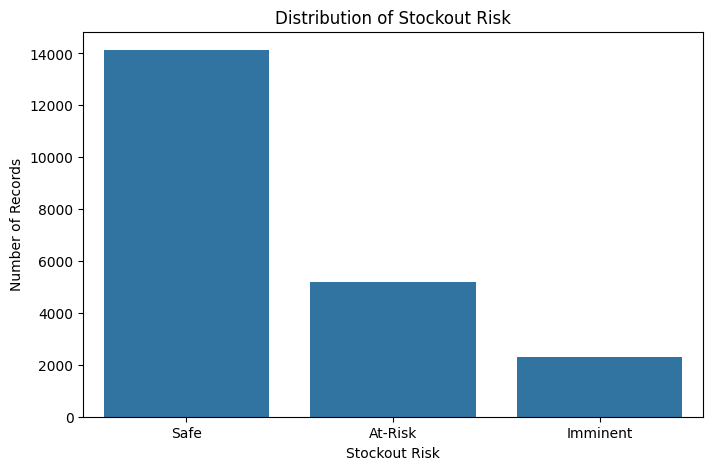

In [51]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='stockout_risk',
    order=['Safe', 'At-Risk', 'Imminent']
)

plt.title('Distribution of Stockout Risk')
plt.xlabel('Stockout Risk')
plt.ylabel('Number of Records')
plt.show()


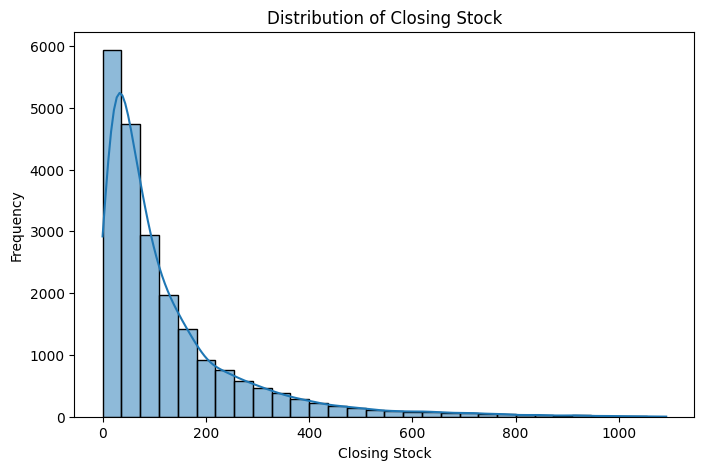

In [52]:

plt.figure(figsize=(8, 5))

sns.histplot(df['closing_stock'], bins=30, kde=True)

plt.title('Distribution of Closing Stock')
plt.xlabel('Closing Stock')
plt.ylabel('Frequency')
plt.show()


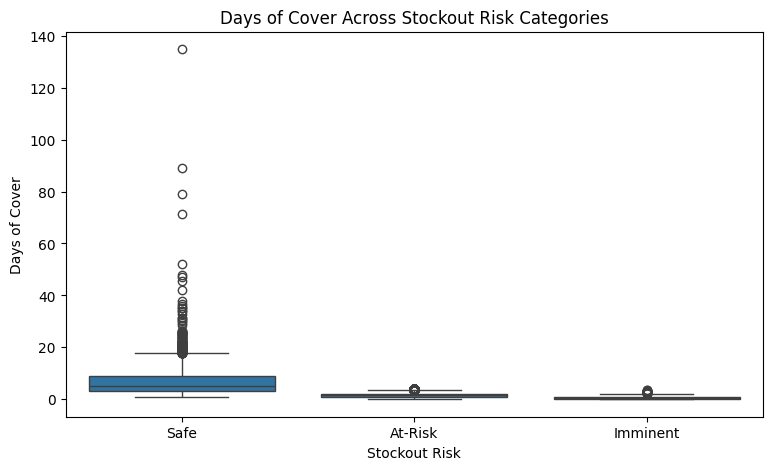

In [54]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='stockout_risk',
    y='days_of_cover_ratio',
    order=['Safe', 'At-Risk', 'Imminent']
)

plt.title('Days of Cover Across Stockout Risk Categories')
plt.xlabel('Stockout Risk')
plt.ylabel('Days of Cover')
plt.show()


In [55]:

risk_percentage = (
    df['stockout_risk']
    .value_counts(normalize=True) * 100
)

print("Stockout Risk Percentage:")
print(risk_percentage.round(2))


Stockout Risk Percentage:
stockout_risk
Safe        65.42
At-Risk     24.01
Imminent    10.57
Name: proportion, dtype: float64


In [57]:

print("Stockout Risk Rules / Distribution")
print(df.groupby('stockout_risk')[
    ['closing_stock', 'reorder_point',
     'days_of_cover', 'units_demanded',
     'sales_velocity_7d']
].mean().round(2))


print("Dataset shape:", df.shape)
print("\nAll columns:")
print(df.columns.tolist())



Stockout Risk Rules / Distribution
               closing_stock  reorder_point  days_of_cover  units_demanded  \
stockout_risk                                                                
At-Risk                74.32          85.12           4.05           18.24   
Imminent               34.73          75.48           1.95           18.54   
Safe                  159.54          67.16          10.64           16.72   

               sales_velocity_7d  
stockout_risk                     
At-Risk                    18.29  
Imminent                   17.54  
Safe                       15.97  
Dataset shape: (21600, 22)

All columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'reorder_numeric', 'recent_reorder', 'day_of_month', 'day_of_week', 'reorder_gap', '

In [58]:

# STEP 13: Feature comparison by stockout risk

features_to_check = [
    'opening_stock',
    'closing_stock',
    'reorder_point',
    'days_of_cover',
    'units_demanded',
    'sales_velocity_7d',
    'reorder_gap',
    'days_of_cover_ratio',
    'recent_reorder'
]

for feature in features_to_check:
    print("\n", "=" * 50)
    print("Feature:", feature)

    print(
        df.groupby('stockout_risk')[feature]
        .mean()
        .round(2)
    )



Feature: opening_stock
stockout_risk
At-Risk      92.56
Imminent     51.22
Safe        152.26
Name: opening_stock, dtype: float64

Feature: closing_stock
stockout_risk
At-Risk      74.32
Imminent     34.73
Safe        159.54
Name: closing_stock, dtype: float64

Feature: reorder_point
stockout_risk
At-Risk     85.12
Imminent    75.48
Safe        67.16
Name: reorder_point, dtype: float64

Feature: days_of_cover
stockout_risk
At-Risk      4.05
Imminent     1.95
Safe        10.64
Name: days_of_cover, dtype: float64

Feature: units_demanded
stockout_risk
At-Risk     18.24
Imminent    18.54
Safe        16.72
Name: units_demanded, dtype: float64

Feature: sales_velocity_7d
stockout_risk
At-Risk     18.29
Imminent    17.54
Safe        15.97
Name: sales_velocity_7d, dtype: float64

Feature: reorder_gap
stockout_risk
At-Risk     10.80
Imminent    40.75
Safe       -92.38
Name: reorder_gap, dtype: float64

Feature: days_of_cover_ratio
stockout_risk
At-Risk     1.66
Imminent    0.68
Safe        6.

In [59]:

# STEP 13: Feature Comparison by Stockout Risk

features_to_check = [
    'opening_stock',
    'closing_stock',
    'reorder_point',
    'days_of_cover',
    'units_demanded',
    'units_sold',
    'sales_velocity_7d',
    'reorder_gap',
    'days_of_cover_ratio',
    'recent_reorder'
]

for feature in features_to_check:
    print("\n" + "=" * 50)
    print("Feature:", feature)

    display(
        df.groupby('stockout_risk')[feature]
        .mean()
        .round(2)
    )



Feature: opening_stock


,opening_stock
stockout_risk,
At-Risk,92.56
Imminent,51.22
Safe,152.26



Feature: closing_stock


,closing_stock
stockout_risk,
At-Risk,74.32
Imminent,34.73
Safe,159.54



Feature: reorder_point


,reorder_point
stockout_risk,
At-Risk,85.12
Imminent,75.48
Safe,67.16


... (10 outputs left out)


Feature: days_of_cover_ratio


,days_of_cover_ratio
stockout_risk,
At-Risk,1.66
Imminent,0.68
Safe,6.46



Feature: recent_reorder


,recent_reorder
stockout_risk,
At-Risk,0.32
Imminent,0.56
Safe,0.13


In [60]:

# STEP 14: Verify Dataset and Required Features

print("Dataset Shape:", df.shape)

print("\nAll Dataset Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

required_columns = [
    'category',
    'reliability_score',
    'event_type',
    'is_perishable',
    'festive_relevant'
]

print("\nRequired Feature Availability:")
for col in required_columns:
    print(col, ":", col in df.columns)


Dataset Shape: (21600, 22)

All Dataset Columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'reorder_numeric', 'recent_reorder', 'day_of_month', 'day_of_week', 'reorder_gap', 'days_of_cover_ratio']

Missing Values:
date                           0
store_id                       0
sku_id                         0
supplier_id                    0
opening_stock                  0
units_demanded                 0
units_sold                     0
closing_stock                  0
reorder_point                  0
reorder_placed                 0
lead_time_days_expected        0
lead_time_days_actual      19899
sales_velocity_7d              0
days_of_cover                  0
is_festival_week               0
stockout_risk                  0
reorder_numeric           

In [61]:

# Merge All Five Datasets

# Start with the main inventory dataset
df = inventory.copy()

# Make sure date columns have matching formats
df['date'] = pd.to_datetime(df['date'])
events['date'] = pd.to_datetime(events['date'])

# Merge store information
df = df.merge(
    stores,
    on='store_id',
    how='left',
    validate='many_to_one'
)

# Merge SKU information
df = df.merge(
    skus,
    on=['sku_id', 'supplier_id'],
    how='left',
    validate='many_to_one'
)

# Merge supplier information
df = df.merge(
    suppliers,
    on='supplier_id',
    how='left',
    validate='many_to_one'
)

# Merge event information
df = df.merge(
    events,
    on='date',
    how='left',
    validate='many_to_one'
)

# Validate final dataset
print("FINAL MERGED DATASET")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated(
    subset=['date', 'store_id', 'sku_id']
).sum())


FINAL MERGED DATASET
Shape: (21600, 39)

Columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other']

Missing Values:
date                             0
store_id                         0
sku_id                           0
supplier_id                      0
opening_stock                    0
units_demanded                   0
units_sold                       0
clo

In [62]:
# STEP 15: Merge All Five Datasets

df = inventory.copy()

df['date'] = pd.to_datetime(df['date'])
events['date'] = pd.to_datetime(events['date'])

df = df.merge(
    stores, on='store_id', how='left',
    validate='many_to_one'
)

df = df.merge(
    skus, on=['sku_id', 'supplier_id'], how='left',
    validate='many_to_one'
)

df = df.merge(
    suppliers, on='supplier_id', how='left',
    validate='many_to_one'
)

df = df.merge(
    events, on='date', how='left',
    validate='many_to_one'
)

print("FINAL MERGED DATASET")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:",
      df.duplicated(subset=['date', 'store_id', 'sku_id']).sum())

FINAL MERGED DATASET
Shape: (21600, 39)

Columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other']

Missing Values:
date                             0
store_id                         0
sku_id                           0
supplier_id                      0
opening_stock                    0
units_demanded                   0
units_sold                       0
clo

In [63]:

# STEP 16: Clean Supplier Reliability

# Convert reliability_score into numeric format
df['reliability_score'] = pd.to_numeric(
    df['reliability_score'],
    errors='coerce'
)

# Fill missing reliability using the median of each SKU category
df['supplier_reliability_clean'] = (
    df.groupby('category')['reliability_score']
      .transform(lambda x: x.fillna(x.median()))
)

# If any missing values remain, use the overall median
df['supplier_reliability_clean'] = (
    df['supplier_reliability_clean']
      .fillna(df['reliability_score'].median())
)

print("Missing reliability values before cleaning:",
      df['reliability_score'].isna().sum())

print("Missing values after cleaning:",
      df['supplier_reliability_clean'].isna().sum())

print("\nCleaned reliability summary:")
print(df['supplier_reliability_clean'].describe())


Missing reliability values before cleaning: 5040
Missing values after cleaning: 0

Cleaned reliability summary:
count    21600.000000
mean         0.757667
std          0.105980
min          0.630000
25%          0.690000
50%          0.700000
75%          0.910000
max          0.930000
Name: supplier_reliability_clean, dtype: float64


In [64]:
print(df['reorder_placed'].value_counts(dropna=False))

reorder_placed
N    19899
Y     1701
Name: count, dtype: int64


In [77]:
for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        print(name, value.shape)

stores (12, 8)
skus (60, 9)
suppliers (15, 6)
events (30, 5)
inventory (21600, 16)
df (21600, 16)
festival_analysis (2, 3)
supplier_analysis (3, 3)
perishable_analysis (2, 3)


In [80]:
print(df.shape)
print('reliability_score' in df.columns)
print('category' in df.columns)

(21600, 16)
False
False


Create date features

In [81]:
df['date'] = pd.to_datetime(df['date'])

df['day_of_month'] = df['date'].dt.day
df['day_of_week'] = df['date'].dt.dayofweek

print(df[['date', 'day_of_month', 'day_of_week']].head())

print("\nMissing date features:")
print(df[['day_of_month', 'day_of_week']].isnull().sum())

        date  day_of_month  day_of_week
0 2026-10-01             1            3
1 2026-10-02             2            4
2 2026-10-03             3            5
3 2026-10-04             4            6
4 2026-10-05             5            0

Missing date features:
day_of_month    0
day_of_week     0
dtype: int64


In [83]:
import pandas as pd

for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        print(name, value.shape)


stores (12, 8)
skus (60, 9)
suppliers (15, 6)
events (30, 5)
inventory (21600, 16)
df (21600, 18)
festival_analysis (2, 3)
supplier_analysis (3, 3)
perishable_analysis (2, 3)


In [85]:
import pandas as pd

print("Available DataFrames:\n")

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        print(f"Variable: {name} | Shape: {value.shape}")



Available DataFrames:

Variable: stores | Shape: (12, 8)
Variable: skus | Shape: (60, 9)
Variable: suppliers | Shape: (15, 6)
Variable: events | Shape: (30, 5)
Variable: inventory | Shape: (21600, 16)
Variable: df | Shape: (21600, 18)
Variable: festival_analysis | Shape: (2, 3)
Variable: supplier_analysis | Shape: (3, 3)
Variable: perishable_analysis | Shape: (2, 3)


In [90]:
inventory['date'] = pd.to_datetime(inventory['date'])
events['date'] = pd.to_datetime(events['date'])

In [91]:
# Start with inventory
final_df = inventory.copy()

# Merge stores
final_df = final_df.merge(
    stores,
    on='store_id',
    how='left'
)

# Merge SKUs
final_df = final_df.merge(
    skus,
    on='sku_id',
    how='left',
    suffixes=('', '_sku')
)

# Merge suppliers
final_df = final_df.merge(
    suppliers,
    on='supplier_id',
    how='left'
)

# Merge events
final_df = final_df.merge(
    events,
    on='date',
    how='left'
)

# Verify
print("Final dataset shape:", final_df.shape)
print("Duplicate records:", final_df.duplicated().sum())

print("\nMissing values:")
print(final_df.isnull().sum())

display(final_df.head())

Final dataset shape: (21600, 40)
Duplicate records: 0

Missing values:
date                             0
store_id                         0
sku_id                           0
supplier_id                      0
opening_stock                    0
units_demanded                   0
units_sold                       0
closing_stock                    0
reorder_point                    0
reorder_placed                   0
lead_time_days_expected          0
lead_time_days_actual        19899
sales_velocity_7d                0
days_of_cover                    0
is_festival_week                 0
stockout_risk                    0
city                             0
city_display                     0
city_tier                        0
store_size                       0
sqft                             0
opened_year                      0
baseline_daily_orders            0
sku_name                         0
category                         0
unit_price_inr                   0
shelf_life_days    

,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,...,supplier_id_sku,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days,event_name,event_type,demand_multiplier_festive,demand_multiplier_other
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0


In [95]:
# Remove any existing supplier columns from df
supplier_columns = [
    'supplier_name',
    'categories_supplied',
    'reliability_score',
    'base_lead_time_days',
    'lead_time_variance_days'
]

df = df.drop(
    columns=[c for c in supplier_columns if c in df.columns]
)

# Restore supplier information
df = df.merge(
    suppliers,
    on='supplier_id',
    how='left',
    validate='many_to_one'
)

print("Dataset shape:", df.shape)
print("Reliability column exists:",
      'reliability_score' in df.columns)

Dataset shape: (21600, 23)
Reliability column exists: True


In [98]:
print("Dataset shape:", df.shape)

print("\nAll columns:")
for col in df.columns:
    print(col)


Dataset shape: (21600, 23)

All columns:
date
store_id
sku_id
supplier_id
opening_stock
units_demanded
units_sold
closing_stock
reorder_point
reorder_placed
lead_time_days_expected
lead_time_days_actual
sales_velocity_7d
days_of_cover
is_festival_week
stockout_risk
day_of_month
day_of_week
supplier_name
categories_supplied
reliability_score
base_lead_time_days
lead_time_variance_days


In [99]:
print(df.isnull().sum())

date                           0
store_id                       0
sku_id                         0
supplier_id                    0
opening_stock                  0
units_demanded                 0
units_sold                     0
closing_stock                  0
reorder_point                  0
reorder_placed                 0
lead_time_days_expected        0
lead_time_days_actual      19899
sales_velocity_7d              0
days_of_cover                  0
is_festival_week               0
stockout_risk                  0
day_of_month                   0
day_of_week                    0
supplier_name                  0
categories_supplied            0
reliability_score           5040
base_lead_time_days            0
lead_time_variance_days        0
dtype: int64


In [100]:
print("Inventory:", inventory.shape)
print("Stores:", stores.shape)
print("SKUs:", skus.shape)
print("Suppliers:", suppliers.shape)
print("Events:", events.shape)

print("\nInventory columns:")
print(inventory.columns.tolist())

print("\nStores columns:")
print(stores.columns.tolist())

print("\nSKUs columns:")
print(skus.columns.tolist())

print("\nEvents columns:")
print(events.columns.tolist())

Inventory: (21600, 16)
Stores: (12, 8)
SKUs: (60, 9)
Suppliers: (15, 6)
Events: (30, 5)

Inventory columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']

Stores columns:
['store_id', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders']

SKUs columns:
['sku_id', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_id']

Events columns:
['date', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other']


In [102]:
# Convert dates
inventory['date'] = pd.to_datetime(inventory['date'])
events['date'] = pd.to_datetime(events['date'])

# Start with inventory
final_df = inventory.copy()

# Merge store details
final_df = final_df.merge(
    stores,
    on='store_id',
    how='left'
)

# Merge SKU details
final_df = final_df.merge(
    skus.drop(columns=['supplier_id']),
    on='sku_id',
    how='left'
)

# Merge supplier details
final_df = final_df.merge(
    suppliers,
    on='supplier_id',
    how='left'
)

# Merge event details
final_df = final_df.merge(
    events,
    on='date',
    how='left'
)

# Replace old df
df = final_df.copy()

# Check results
print("Final dataset shape:", df.shape)
print("Duplicate records:", df.duplicated().sum())

print("\nAll columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Final dataset shape: (21600, 39)
Duplicate records: 0

All columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other']

Missing values:
date                             0
store_id                         0
sku_id                           0
supplier_id                      0
opening_stock                    0
units_demanded                   0
units_sold          

In [103]:
# 1. Convert reliability_score into numeric format
df['reliability_score'] = pd.to_numeric(
    df['reliability_score'],
    errors='coerce'
)

# 2. Fill missing values using category-wise median
df['supplier_reliability_clean'] = (
    df.groupby('category')['reliability_score']
    .transform(lambda x: x.fillna(x.median()))
)

# 3. Fill any remaining missing values with overall median
overall_median = df['reliability_score'].median()

df['supplier_reliability_clean'] = (
    df['supplier_reliability_clean'].fillna(overall_median)
)

# 4. Convert date into datetime format
df['date'] = pd.to_datetime(df['date'])

# 5. Create date features
df['day_of_month'] = df['date'].dt.day
df['day_of_week'] = df['date'].dt.dayofweek

# 6. Verify
print("Dataset shape:", df.shape)

print("\nMissing values in cleaned reliability:")
print(df['supplier_reliability_clean'].isnull().sum())

print("\nDate features:")
print(df[['date', 'day_of_month', 'day_of_week']].head())

print("\nReliability values:")
print(df[['category', 'reliability_score',
          'supplier_reliability_clean']].head(10))

Dataset shape: (21600, 42)

Missing values in cleaned reliability:
0

Date features:
        date  day_of_month  day_of_week
0 2026-10-01             1            3
1 2026-10-02             2            4
2 2026-10-03             3            5
3 2026-10-04             4            6
4 2026-10-05             5            0

Reliability values:
              category  reliability_score  supplier_reliability_clean
0  Fruits & Vegetables               0.83                        0.83
1  Fruits & Vegetables               0.83                        0.83
2  Fruits & Vegetables               0.83                        0.83
3  Fruits & Vegetables               0.83                        0.83
4  Fruits & Vegetables               0.83                        0.83
5  Fruits & Vegetables               0.83                        0.83
6  Fruits & Vegetables               0.83                        0.83
7  Fruits & Vegetables               0.83                        0.83
8  Fruits & Vegetables  

## **MACHINE LEARNING**

In [104]:
features = [
    'opening_stock',
    'reorder_point',
    'lead_time_days_expected',
    'sales_velocity_7d',
    'is_festival_week',
    'city_tier',
    'store_size',
    'baseline_daily_orders',
    'category',
    'unit_price_inr',
    'shelf_life_days',
    'is_perishable',
    'festive_relevant',
    'popularity_tier',
    'supplier_reliability_clean',
    'base_lead_time_days',
    'lead_time_variance_days',
    'demand_multiplier_festive',
    'demand_multiplier_other',
    'day_of_month',
    'day_of_week'
]

# Input features and target
X = df[features]
y = df['stockout_risk']

print("Number of features:", len(features))
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Number of features: 21
X shape: (21600, 21)
y shape: (21600,)

Target distribution:
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64


In [105]:
# Training and testing conditions
train_mask = df['date'] <= '2026-10-23'
test_mask = df['date'] >= '2026-10-24'

# Split features
X_train = X[train_mask]
X_test = X[test_mask]

# Split target
y_train = y[train_mask]
y_test = y[test_mask]

# Display results
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (16560, 21)
Testing data shape: (5040, 21)

Training target distribution:
stockout_risk
Safe        10992
At-Risk      4060
Imminent     1508
Name: count, dtype: int64

Testing target distribution:
stockout_risk
Safe        3139
At-Risk     1126
Imminent     775
Name: count, dtype: int64


### **LogisticRegression**

In [110]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# All categorical columns
categorical_features = [
    'is_festival_week',
    'city_tier',
    'store_size',
    'category',
    'is_perishable',
    'festive_relevant',
    'popularity_tier'
]

# Numerical columns
numerical_features = [
    col for col in features
    if col not in categorical_features
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000))
    ]
)

print("Corrected preprocessing pipeline created!")
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

Corrected preprocessing pipeline created!
Categorical features: 7
Numerical features: 14


In [109]:
# Check data types of all 21 features
print("Feature data types:\n")
print(X.dtypes)

# Find columns stored as text
print("\nColumns containing text values:\n")

for col in features:
    if X[col].dtype == 'object':
        print(f"\nColumn: {col}")
        print("Unique values:", X[col].unique()[:15])

Feature data types:

opening_stock                 float64
reorder_point                 float64
lead_time_days_expected         int64
sales_velocity_7d             float64
is_festival_week               object
city_tier                      object
store_size                     object
baseline_daily_orders           int64
category                       object
unit_price_inr                float64
shelf_life_days                 int64
is_perishable                  object
festive_relevant               object
popularity_tier                object
supplier_reliability_clean    float64
base_lead_time_days             int64
lead_time_variance_days       float64
demand_multiplier_festive     float64
demand_multiplier_other       float64
day_of_month                    int32
day_of_week                     int32
dtype: object

Columns containing text values:


Column: is_festival_week
Unique values: ['N' 'Y']

Column: city_tier
Unique values: ['Tier1']

Column: store_size
Unique values: ['L

In [111]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed successfully!")

Logistic Regression training completed successfully!


In [112]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = logistic_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 71.25 %

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.52      0.26      0.35      1126
    Imminent       0.61      0.57      0.59       775
        Safe       0.76      0.91      0.83      3139

    accuracy                           0.71      5040
   macro avg       0.63      0.58      0.59      5040
weighted avg       0.68      0.71      0.68      5040


Confusion Matrix:
[[ 293   87  746]
 [ 175  442  158]
 [  93  190 2856]]


# **Balanced Model**

In [113]:
balanced_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            class_weight='balanced'
        ))
    ]
)

balanced_model.fit(X_train, y_train)

print("Balanced Logistic Regression training completed!")

Balanced Logistic Regression training completed!


In [114]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_balanced = balanced_model.predict(X_test)

print("Balanced Model Accuracy:",
      round(accuracy_score(y_test, y_pred_balanced) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

Balanced Model Accuracy: 75.62 %

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.75      0.49      0.59      1126
    Imminent       0.44      0.86      0.58       775
        Safe       0.93      0.83      0.87      3139

    accuracy                           0.76      5040
   macro avg       0.71      0.73      0.68      5040
weighted avg       0.81      0.76      0.77      5040


Confusion Matrix:
[[ 551  373  202]
 [ 103  667    5]
 [  78  468 2593]]


In [115]:
import joblib

joblib.dump(logistic_model, 'original_logistic_model.pkl')
joblib.dump(balanced_model, 'balanced_logistic_model.pkl')

print("Both Logistic Regression models saved successfully!")

Both Logistic Regression models saved successfully!


# **Random Forest**

In [116]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Preprocessing for Random Forest
rf_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Create Random Forest model
rf_model = Pipeline(
    steps=[
        ('preprocessor', rf_preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=300,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")

Random Forest training completed successfully!


In [117]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 73.45 %

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.61      0.43      0.50      1126
    Imminent       0.62      0.34      0.44       775
        Safe       0.77      0.94      0.85      3139

    accuracy                           0.73      5040
   macro avg       0.67      0.57      0.60      5040
weighted avg       0.71      0.73      0.71      5040


Confusion Matrix:
[[ 486   61  579]
 [ 229  266  280]
 [  84  105 2950]]


In [118]:
joblib.dump(rf_model, 'random_forest_model.pkl')

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


# **xgboost**

In [119]:
%pip install -q xgboost

import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("XGBoost imported successfully!")

XGBoost version: 3.4.1
XGBoost imported successfully!


In [121]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Class mapping:")

for i, label in enumerate(label_encoder.classes_):
    print(label, "=", i)

Class mapping:
At-Risk = 0
Imminent = 1
Safe = 2


In [122]:
xgb_model.fit(X_train, y_train_encoded)

print("XGBoost training completed successfully!")

XGBoost training completed successfully!


In [123]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict test data
y_pred_xgb_encoded = xgb_model.predict(X_test)

# Convert numerical predictions back to category names
y_pred_xgb = label_encoder.inverse_transform(
    y_pred_xgb_encoded.astype(int)
)

# Accuracy
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:",
      round(xgb_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    labels=label_encoder.classes_
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_xgb,
    labels=label_encoder.classes_
))

XGBoost Accuracy: 82.0 %

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.71      0.70      0.71      1126
    Imminent       0.69      0.48      0.57       775
        Safe       0.88      0.95      0.91      3139

    accuracy                           0.82      5040
   macro avg       0.76      0.71      0.73      5040
weighted avg       0.81      0.82      0.81      5040


Confusion Matrix:
[[ 788   68  270]
 [ 253  372  150]
 [  65  101 2973]]


In [124]:
import joblib

joblib.dump(xgb_model, 'xgboost_stockout_model.pkl')
joblib.dump(label_encoder, 'xgboost_label_encoder.pkl')

print("XGBoost model and label encoder saved successfully!")


XGBoost model and label encoder saved successfully!


In [125]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create baseline model
baseline_model = DummyClassifier(strategy='most_frequent')

# Train model
baseline_model.fit(X_train, y_train)

# Predict
y_pred_baseline = baseline_model.predict(X_test)

# Evaluate
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print("Majority Classifier Accuracy:",
      round(baseline_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline))

Majority Classifier Accuracy: 62.28 %

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.00      0.00      0.00      1126
    Imminent       0.00      0.00      0.00       775
        Safe       0.62      1.00      0.77      3139

    accuracy                           0.62      5040
   macro avg       0.21      0.33      0.26      5040
weighted avg       0.39      0.62      0.48      5040



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [126]:
import joblib

joblib.dump(baseline_model, 'majority_classifier.pkl')

print("Majority Classifier saved successfully!")

Majority Classifier saved successfully!


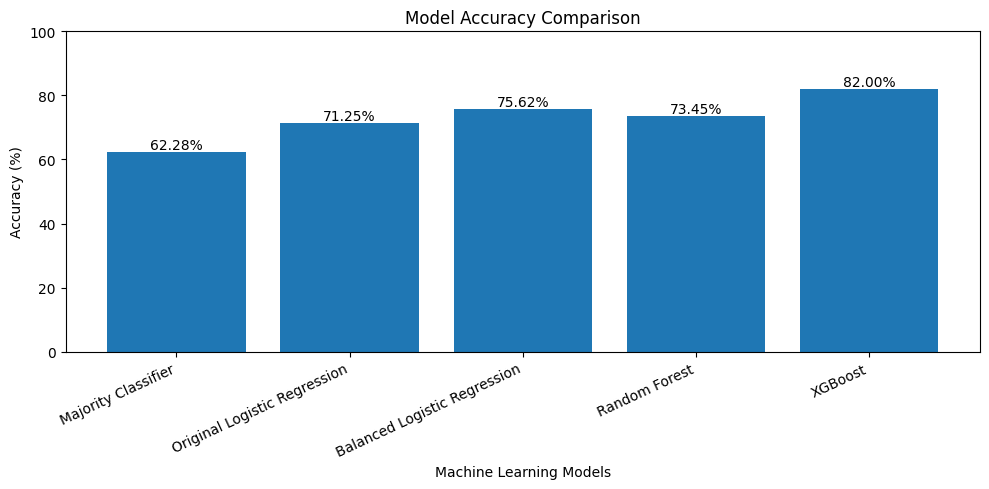

In [127]:
import matplotlib.pyplot as plt

models = [
    'Majority Classifier',
    'Original Logistic Regression',
    'Balanced Logistic Regression',
    'Random Forest',
    'XGBoost'
]

accuracies = [
    baseline_accuracy * 100,
    71.25,
    75.62,
    73.45,
    xgb_accuracy * 100
]

plt.figure(figsize=(10, 5))

bars = plt.bar(models, accuracies)

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

plt.xticks(rotation=25, ha='right')

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f'{accuracy:.2f}%',
        ha='center'
    )

plt.tight_layout()
plt.show()

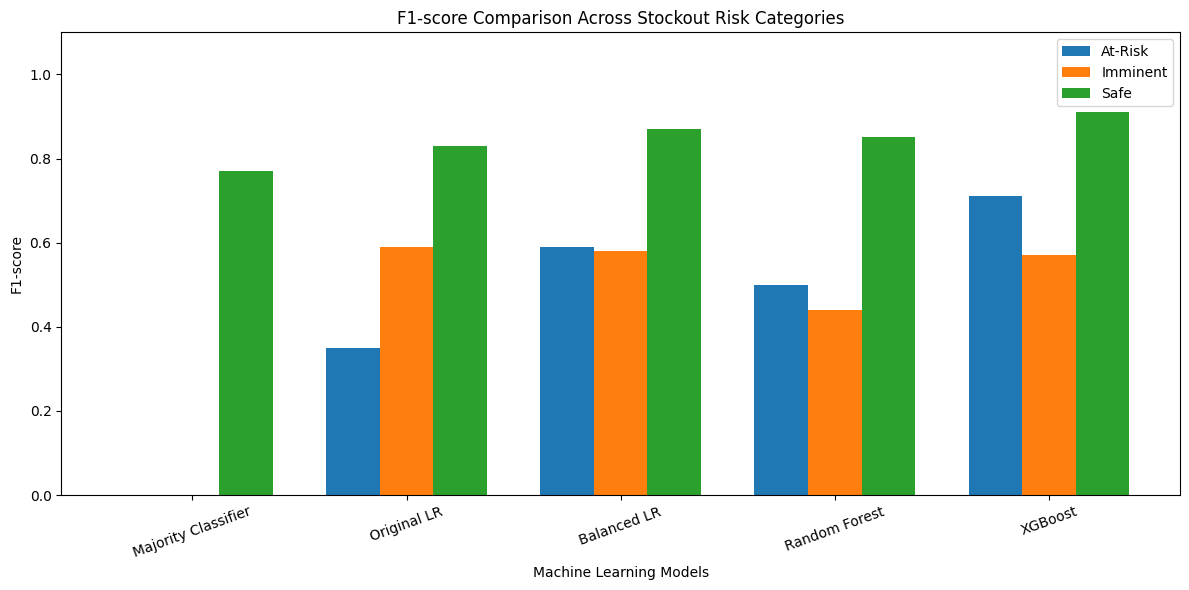

In [128]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    'Majority Classifier',
    'Original LR',
    'Balanced LR',
    'Random Forest',
    'XGBoost'
]

at_risk_f1 = [0.00, 0.35, 0.59, 0.50, 0.71]
imminent_f1 = [0.00, 0.59, 0.58, 0.44, 0.57]
safe_f1 = [0.77, 0.83, 0.87, 0.85, 0.91]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(x - width, at_risk_f1, width, label='At-Risk')
plt.bar(x, imminent_f1, width, label='Imminent')
plt.bar(x + width, safe_f1, width, label='Safe')

plt.xlabel('Machine Learning Models')
plt.ylabel('F1-score')
plt.title('F1-score Comparison Across Stockout Risk Categories')

plt.xticks(x, models, rotation=20)
plt.ylim(0, 1.1)
plt.legend()
plt.tight_layout()
plt.show()

In [129]:
!pip install shap

In [130]:
import shap

print("SHAP imported successfully!")

SHAP imported successfully!


In [131]:
# Extract the trained preprocessing component
xgb_preprocessor = xgb_model.named_steps['preprocessor']

# Transform test data
X_test_transformed = xgb_preprocessor.transform(X_test)

# Get feature names after preprocessing
feature_names = xgb_preprocessor.get_feature_names_out()

print("Transformed test data shape:", X_test_transformed.shape)
print("Number of features:", len(feature_names))
print("\nFeature names:")
print(feature_names)

Transformed test data shape: (5040, 35)
Number of features: 35

Feature names:
['num__opening_stock' 'num__reorder_point' 'num__lead_time_days_expected'
 'num__sales_velocity_7d' 'num__baseline_daily_orders'
 'num__unit_price_inr' 'num__shelf_life_days'
 'num__supplier_reliability_clean' 'num__base_lead_time_days'
 'num__lead_time_variance_days' 'num__demand_multiplier_festive'
 'num__demand_multiplier_other' 'num__day_of_month' 'num__day_of_week'
 'cat__is_festival_week_N' 'cat__is_festival_week_Y'
 'cat__city_tier_Tier1' 'cat__store_size_Large' 'cat__store_size_Medium'
 'cat__store_size_Small' 'cat__category_Bakery' 'cat__category_Beverages'
 'cat__category_Dairy' 'cat__category_Fruits & Vegetables'
 'cat__category_Home Care' 'cat__category_Personal Care'
 'cat__category_Snacks' 'cat__category_Staples' 'cat__is_perishable_N'
 'cat__is_perishable_Y' 'cat__festive_relevant_N'
 'cat__festive_relevant_Y' 'cat__popularity_tier_High'
 'cat__popularity_tier_Low' 'cat__popularity_tier_Medium

In [132]:
# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(
    xgb_model.named_steps['classifier']
)

# Select 500 test records for SHAP analysis
X_shap = X_test_transformed[:500]

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


In [134]:
print("SHAP values type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    for i, values in enumerate(shap_values):
        print(f"Class {i} shape:", values.shape)
else:
    print("SHAP values shape:", shap_values.shape)

print("Feature names count:", len(feature_names))

SHAP values type: <class 'numpy.ndarray'>
SHAP values shape: (500, 35, 3)
Feature names count: 35


Top 15 Important Features:
                        Feature  Importance
             num__opening_stock    1.163218
         num__sales_velocity_7d    0.638851
             num__reorder_point    0.306950
   num__lead_time_days_expected    0.276497
num__supplier_reliability_clean    0.215342
 num__demand_multiplier_festive    0.062100
     num__baseline_daily_orders    0.055824
              num__day_of_month    0.045884
   num__lead_time_variance_days    0.030538
   num__demand_multiplier_other    0.024725
            num__unit_price_inr    0.022954
           num__shelf_life_days    0.020595
               num__day_of_week    0.016280
    cat__popularity_tier_Medium    0.008241
       cat__popularity_tier_Low    0.005877


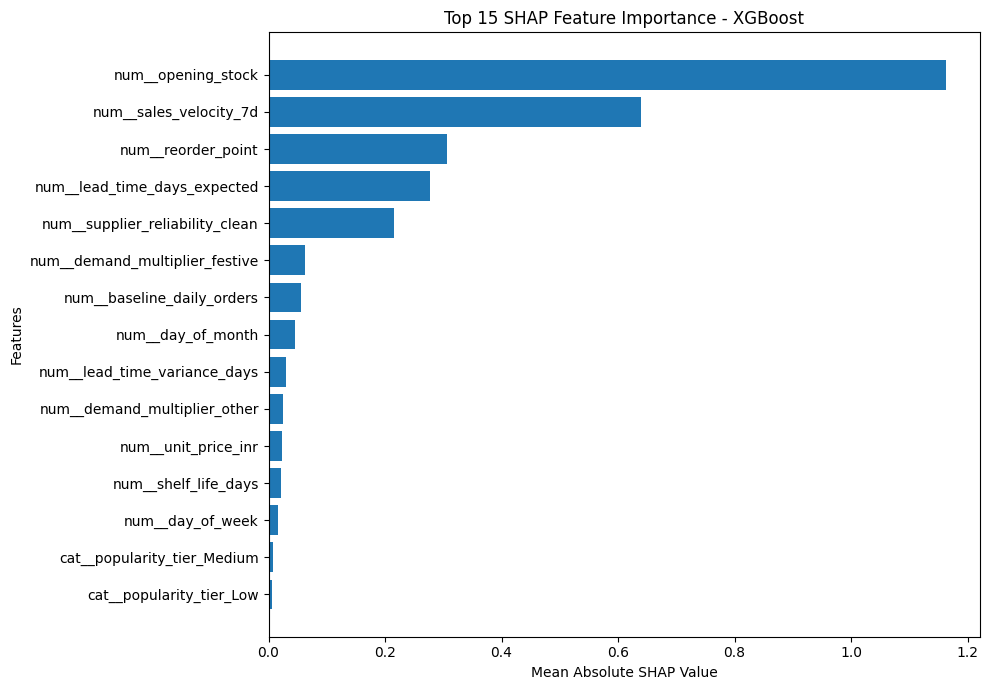

In [135]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate mean absolute SHAP importance
feature_importance = np.abs(shap_values).mean(axis=(0, 2))

# Create dataframe
shap_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

# Sort features by importance
shap_df = shap_df.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
print("Top 15 Important Features:")
print(shap_df.head(15).to_string(index=False))

# Plot feature importance
plt.figure(figsize=(10, 7))

plt.barh(
    shap_df.head(15)['Feature'][::-1],
    shap_df.head(15)['Importance'][::-1]
)

plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Features')
plt.title('Top 15 SHAP Feature Importance - XGBoost')

plt.tight_layout()
plt.show()

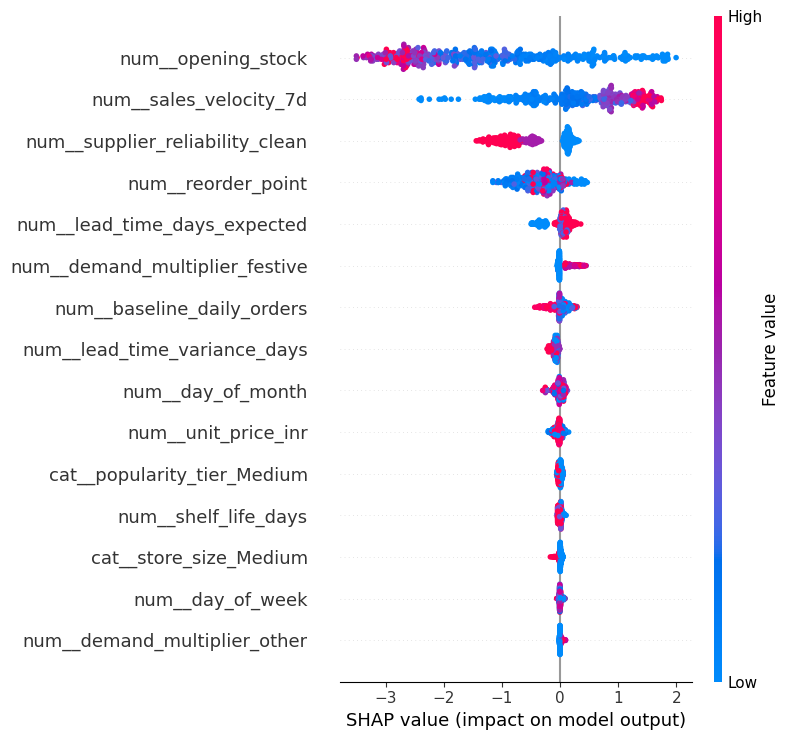

In [136]:
# Identify Imminent class index
imminent_index = list(label_encoder.classes_).index('Imminent')

# SHAP summary plot for Imminent class
shap.summary_plot(
    shap_values[:, :, imminent_index],
    X_shap,
    feature_names=feature_names,
    max_display=15
)

In [140]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Evaluate XGBoost predictions
print("QUICKCART - XGBOOST MODEL EVALUATION")

print("\nAccuracy:",
      round(accuracy_score(y_test, y_pred_xgb) * 100, 2), "%")

print("Macro Precision:",
      round(precision_score(y_test, y_pred_xgb,
                            average='macro'), 3))

print("Macro Recall:",
      round(recall_score(y_test, y_pred_xgb,
                         average='macro'), 3))

print("Macro F1-score:",
      round(f1_score(y_test, y_pred_xgb,
                     average='macro'), 3))

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    labels=label_encoder.classes_,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_xgb,
    labels=label_encoder.classes_
))

QUICKCART - XGBOOST MODEL EVALUATION

Accuracy: 82.0 %
Macro Precision: 0.759
Macro Recall: 0.709
Macro F1-score: 0.727

Detailed Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.71      0.70      0.71      1126
    Imminent       0.69      0.48      0.57       775
        Safe       0.88      0.95      0.91      3139

    accuracy                           0.82      5040
   macro avg       0.76      0.71      0.73      5040
weighted avg       0.81      0.82      0.81      5040


Confusion Matrix:
[[ 788   68  270]
 [ 253  372  150]
 [  65  101 2973]]


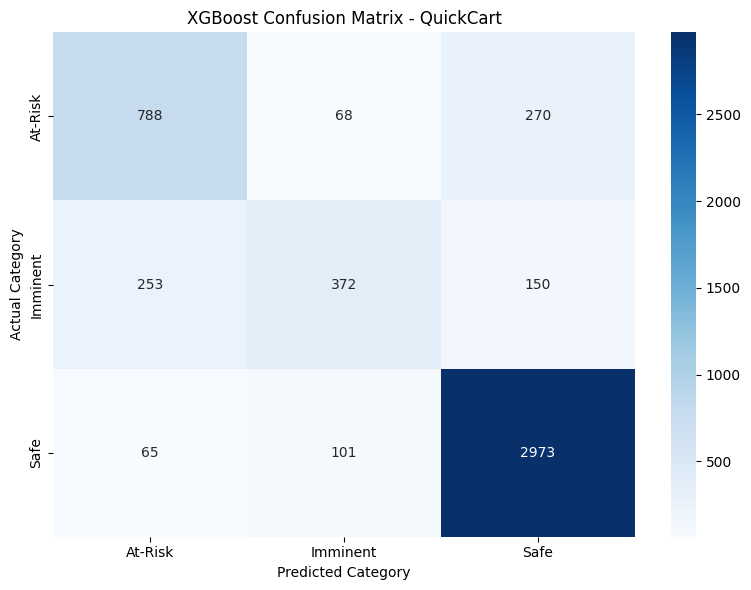

In [141]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_xgb,
    labels=['At-Risk', 'Imminent', 'Safe']
)

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['At-Risk', 'Imminent', 'Safe'],
    yticklabels=['At-Risk', 'Imminent', 'Safe']
)

plt.title('XGBoost Confusion Matrix - QuickCart')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')

plt.tight_layout()
plt.show()

In [142]:
# Get prediction probabilities
y_prob_xgb = xgb_model.predict_proba(X_test)

# Display class order
print("Class order:", label_encoder.classes_)

# Display first 10 prediction probabilities
probability_df = pd.DataFrame(
    y_prob_xgb[:10],
    columns=label_encoder.classes_
)

print("\nPrediction Probabilities:")
print(probability_df.round(3))

Class order: ['At-Risk' 'Imminent' 'Safe']

Prediction Probabilities:
   At-Risk  Imminent   Safe
0    0.625     0.090  0.284
1    0.467     0.295  0.238
2    0.001     0.000  0.999
3    0.001     0.000  0.999
4    0.002     0.000  0.998
5    0.005     0.000  0.995
6    0.015     0.001  0.984
7    0.021     0.479  0.500
8    0.015     0.012  0.973
9    0.186     0.024  0.789


In [143]:
import numpy as np
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score

# Get dates corresponding to training records
train_dates = df.loc[X_train.index, 'date']

# Divide training period chronologically
unique_dates = sorted(train_dates.unique())
split_position = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_position]

fit_mask = train_dates < split_date
val_mask = train_dates >= split_date

X_fit = X_train.loc[fit_mask]
X_val = X_train.loc[val_mask]

y_fit = y_train.loc[fit_mask]
y_val = y_train.loc[val_mask]

# Train a separate model for validation
validation_model = clone(xgb_model)

y_fit_encoded = label_encoder.transform(y_fit)

validation_model.fit(X_fit, y_fit_encoded)

# Get validation probabilities
val_probabilities = validation_model.predict_proba(X_val)

# Find Imminent class index
imminent_index = list(label_encoder.classes_).index('Imminent')

# Test different thresholds
results = []

for threshold in np.arange(0.20, 0.71, 0.05):

    predictions = label_encoder.inverse_transform(
        validation_model.predict_proba(X_val).argmax(axis=1)
    )

    imminent_mask = (
        val_probabilities[:, imminent_index] >= threshold
    )

    predictions[imminent_mask] = 'Imminent'

    results.append({
        'Threshold': round(threshold, 2),
        'Precision': precision_score(
            y_val, predictions,
            labels=['Imminent'],
            average='macro',
            zero_division=0
        ),
        'Recall': recall_score(
            y_val, predictions,
            labels=['Imminent'],
            average='macro',
            zero_division=0
        ),
        'F1_Score': f1_score(
            y_val, predictions,
            labels=['Imminent'],
            average='macro',
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

print("IMMINENT THRESHOLD COMPARISON")
print(threshold_results.round(3).to_string(index=False))

IMMINENT THRESHOLD COMPARISON
 Threshold  Precision  Recall  F1_Score
      0.20      0.459   0.728     0.563
      0.25      0.496   0.658     0.565
      0.30      0.529   0.596     0.561
      0.35      0.547   0.513     0.529
      0.40      0.560   0.457     0.503
      0.45      0.573   0.414     0.480
      0.50      0.569   0.392     0.464
      0.55      0.569   0.392     0.464
      0.60      0.569   0.392     0.464
      0.65      0.569   0.392     0.464
      0.70      0.569   0.392     0.464


In [144]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Get test probabilities
test_probabilities = xgb_model.predict_proba(X_test)

# Normal predictions
adjusted_predictions = label_encoder.inverse_transform(
    np.argmax(test_probabilities, axis=1)
)

# Apply selected Imminent threshold
imminent_index = list(label_encoder.classes_).index('Imminent')

selected_threshold = 0.25

imminent_mask = (
    test_probabilities[:, imminent_index] >= selected_threshold
)

adjusted_predictions[imminent_mask] = 'Imminent'

# Evaluate adjusted predictions
print("QUICKCART - ADJUSTED XGBOOST EVALUATION")

print("\nAccuracy:",
      round(accuracy_score(y_test, adjusted_predictions) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    adjusted_predictions,
    labels=label_encoder.classes_,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    adjusted_predictions,
    labels=label_encoder.classes_
))

QUICKCART - ADJUSTED XGBOOST EVALUATION

Accuracy: 81.65 %

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.76      0.62      0.68      1126
    Imminent       0.59      0.73      0.65       775
        Safe       0.90      0.91      0.91      3139

    accuracy                           0.82      5040
   macro avg       0.75      0.75      0.75      5040
weighted avg       0.82      0.82      0.82      5040


Confusion Matrix:
[[ 700  167  259]
 [ 168  565   42]
 [  57  232 2850]]


In [145]:
import joblib

# Save selected threshold
quickcart_settings = {
    'model_name': 'XGBoost',
    'imminent_threshold': 0.25,
    'classes': list(label_encoder.classes_)
}

joblib.dump(
    quickcart_settings,
    'quickcart_xgboost_settings.pkl'
)

print("Adjusted XGBoost settings saved successfully!")

Adjusted XGBoost settings saved successfully!


In [146]:
# Create prediction output dataframe
quickcart_predictions = df.loc[X_test.index, [
    'date',
    'store_id',
    'sku_id',
    'opening_stock',
    'reorder_point'
]].copy()

# Add actual and predicted risk
quickcart_predictions['Actual_Risk'] = y_test.values

quickcart_predictions['Predicted_Risk'] = adjusted_predictions

# Add prediction probabilities
quickcart_predictions['At_Risk_Probability'] = test_probabilities[:, 0]
quickcart_predictions['Imminent_Probability'] = test_probabilities[:, 1]
quickcart_predictions['Safe_Probability'] = test_probabilities[:, 2]

# Display first 15 predictions
print("QUICKCART INVENTORY RISK PREDICTIONS")

display(quickcart_predictions.head(15))

QUICKCART INVENTORY RISK PREDICTIONS


,date,store_id,sku_id,opening_stock,reorder_point,Actual_Risk,Predicted_Risk,At_Risk_Probability,Imminent_Probability,Safe_Probability
23,2026-10-24,ST01,SKU001,52.8,36.4,At-Risk,At-Risk,0.625483,0.090456,0.284061
24,2026-10-25,ST01,SKU001,34.8,36.4,Safe,Imminent,0.466892,0.295377,0.237731
25,2026-10-26,ST01,SKU001,188.8,36.4,Safe,Safe,0.000636,0.000035,0.999328
26,2026-10-27,ST01,SKU001,162.8,36.4,Safe,Safe,0.000937,0.000048,0.999015
27,2026-10-28,ST01,SKU001,148.8,36.4,Safe,Safe,0.001567,0.000132,0.998301
28,2026-10-29,ST01,SKU001,131.8,36.4,Safe,Safe,0.004549,0.000192,0.995259
29,2026-10-30,ST01,SKU001,112.8,36.4,Safe,Safe,0.014822,0.001103,0.984075
53,2026-10-24,ST02,SKU001,1.4,4.0,Safe,Imminent,0.020629,0.479284,0.500087
54,2026-10-25,ST02,SKU001,18.6,4.0,Safe,Safe,0.014833,0.011845,0.973322
55,2026-10-26,ST02,SKU001,15.6,4.0,Safe,Safe,0.186318,0.024359,0.789323


This output makes my project practical. Instead of showing only model accuracy, it shows the predicted inventory risk for each SKU in each store on each day.



In [147]:
# Export all prediction results
quickcart_predictions.to_csv(
    'QuickCart_Inventory_Risk_Predictions.csv',
    index=False
)

print("QuickCart prediction results exported successfully!")

# Download the CSV file in Google Colab
from google.colab import files
files.download('QuickCart_Inventory_Risk_Predictions.csv')

QuickCart prediction results exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [148]:
# Check the target column
print("Target column: stockout_risk")

print("\nRisk category counts:")
print(df['stockout_risk'].value_counts())

print("\nRisk category percentages:")
print(df['stockout_risk'].value_counts(normalize=True) * 100)

print("\nSample records:")
display(df[[
    'opening_stock',
    'units_demanded',
    'units_sold',
    'closing_stock',
    'reorder_point',
    'days_of_cover',
    'stockout_risk'
]].head(15))

Target column: stockout_risk

Risk category counts:
stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

Risk category percentages:
stockout_risk
Safe        65.421296
At-Risk     24.009259
Imminent    10.569444
Name: proportion, dtype: float64

Sample records:


,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,days_of_cover,stockout_risk
0,159.9,15,15.0,144.9,36.4,9.66,Safe
1,144.9,10,10.0,134.9,36.4,10.79,Safe
2,134.9,15,15.0,119.9,36.4,8.99,Safe
3,119.9,10,10.0,109.9,36.4,8.79,Safe
4,109.9,9,9.0,100.9,36.4,8.55,Safe
5,100.9,12,12.0,88.9,36.4,7.52,Safe
6,88.9,9,9.0,79.9,36.4,6.99,Safe
7,79.9,13,13.0,66.9,36.4,6.01,Safe
8,66.9,12,12.0,54.9,36.4,4.81,Safe
9,54.9,13,13.0,41.9,36.4,3.76,At-Risk


In [149]:
# Compare inventory values for each risk category
risk_analysis = df.groupby('stockout_risk')[
    ['opening_stock',
     'closing_stock',
     'reorder_point',
     'days_of_cover',
     'sales_velocity_7d']
].agg(['min', 'mean', 'median', 'max'])

display(risk_analysis.round(2))

opening_stock                        closing_stock          \
                        min    mean median     max           min    mean   
stockout_risk                                                              
At-Risk                 1.0   92.56  59.15   782.9           1.0   74.32   
Imminent                0.0   51.22  28.20   510.6           0.0   34.73   
Safe                    0.0  152.26  94.60  1091.6           3.6  159.54   

                             reorder_point                      days_of_cover  \
              median     max           min   mean median    max           min   
stockout_risk                                                                   
At-Risk         45.8   651.9           3.0  85.12   56.3  467.4           1.0   
Imminent        15.2   418.4           3.0  75.48   50.5  422.1           0.0   
Safe           102.3  1091.6           3.0  67.16   41.4  467.4           4.0   

                                    sales_velocity_7d                        
                mean median     max               min   mean median     max  
stockout_risk                                                                
At-Risk         4.05   3.82    8.80              0.75  18.29  12.00  108.14  
Imminent        1.95   1.72    7.88              1.00  17.54  11.43  117.57  
Safe           10.64  10.05  134.85              0.00  15.97  10.71  100.99

In [150]:
# Check average days of cover for each risk category
print("Average days of cover by risk category:")

print(
    df.groupby('stockout_risk')['days_of_cover']
    .agg(['min', 'mean', 'median', 'max'])
    .round(2)
)

# Check risk distribution across days-of-cover ranges
df['cover_range'] = pd.cut(
    df['days_of_cover'],
    bins=[-1, 2, 4, 8, 15, float('inf')],
    labels=['0-2 days', '2-4 days', '4-8 days',
            '8-15 days', 'Above 15 days']
)

display(pd.crosstab(
    df['cover_range'],
    df['stockout_risk'],
    normalize='index'
).round(3) * 100)

Average days of cover by risk category:
               min   mean  median     max
stockout_risk                            
At-Risk        1.0   4.05    3.82    8.80
Imminent       0.0   1.95    1.72    7.88
Safe           4.0  10.64   10.05  134.85


stockout_risk,At-Risk,Imminent,Safe
cover_range,,,
0-2 days,26.4,73.6,0.0
2-4 days,76.9,22.9,0.1
4-8 days,35.0,4.3,60.7
8-15 days,0.0,0.0,100.0
Above 15 days,0.0,0.0,100.0


**QUICKCART WAREHOUSE INVENTORY STOCKOUT RISK**

## ABSTRACT

Inventory management is an important part of warehouse and retail operations. Maintaining insufficient stock can lead to stockouts, while maintaining excess stock can increase storage costs. This project proposes a machine learning-based inventory stockout risk prediction system called QuickCart.

The system combines multiple datasets, including Inventory, Stores, SKUs, Suppliers, and Events, to predict inventory risk for each SKU in each store on a daily basis. The prediction task is formulated as a three-class classification problem with the categories Safe, At-Risk, and Imminent.

Several machine learning approaches, including Logistic Regression, Random Forest, and XGBoost, were implemented and evaluated. XGBoost achieved an accuracy of 82.00% in the original evaluation. An additional threshold adjustment improved the macro F1-score to 0.75 and increased Imminent-risk recall to 0.73. SHAP explainability was used to identify the important features influencing model predictions.

The proposed system can support inventory monitoring by identifying products that may require attention and helping warehouse managers make better stock management decisions.

**Keywords:** Inventory Management, Stockout Prediction, Machine Learning, Multi-Class Classification, XGBoost, Random Forest, SHAP, Explainable AI.

---

## CHAPTER 1 – INTRODUCTION

### 1.1 Introduction

Inventory management plays an important role in retail businesses and warehouse operations. Every store needs to maintain sufficient stock to meet customer demand.

When products are unavailable, businesses may lose sales and customer satisfaction. On the other hand, storing too much inventory can increase operational and storage costs.

Traditional inventory monitoring methods may not identify potential stock risks early enough.

QuickCart uses machine learning techniques to analyse inventory-related information and classify stock conditions into three categories: Safe, At-Risk, and Imminent.

### 1.2 Problem Statement

Retail stores manage multiple products, suppliers, and inventory records every day. Identifying products that may experience stock shortages is a challenging task.

Manual monitoring may not efficiently identify all potential inventory risks.

Therefore, this project develops a machine learning-based classification system to predict daily inventory stockout risk for different products across multiple stores.

### 1.3 Objectives

1. To combine multiple inventory-related datasets into a single dataset.
2. To preprocess the data and perform feature engineering.
3. To classify inventory conditions into Safe, At-Risk, and Imminent categories.
4. To implement and compare different machine learning models.
5. To improve Imminent-risk identification using threshold adjustment.
6. To apply SHAP explainability to identify important prediction features.
7. To generate daily inventory-risk predictions for each store and SKU.

### 1.4 Scope of the Project

The project focuses on daily inventory-risk classification across multiple stores and products.

It considers stock information, supplier reliability, product categories, store characteristics, sales velocity, and event-related demand information.

The system aims to provide useful predictions that can support inventory monitoring and stock management.

---

## CHAPTER 2 – DATASET DESCRIPTION

### 2.1 Dataset Overview

Five different datasets were used in this project.

| Dataset | Description |
|---|---|
| Inventory | Daily stock and sales information |
| Stores | Store location and store characteristics |
| SKUs | Product details and categories |
| Suppliers | Supplier reliability and delivery information |
| Events | Festival and event-related demand information |

### 2.2 Dataset Details

- Inventory dataset: 21,600 records and 16 columns.
- Stores dataset: 12 records and 8 columns.
- SKUs dataset: 60 records and 9 columns.
- Suppliers dataset: 15 records and 6 columns.
- Events dataset: 30 records and 5 columns.

### 2.3 Data Integration

The five datasets were combined using common identifiers.

The following columns were used for merging:

- Store ID
- SKU ID
- Supplier ID
- Date

A left join was used to preserve the inventory records while adding related store, product, supplier, and event information.

The final merged dataset contained **21,600 records and 39 columns**.

### 2.4 Data Preprocessing

The following preprocessing activities were performed:

1. Converted date columns into datetime format.
2. Checked and removed duplicate records.
3. Handled missing supplier reliability values.
4. Created additional date-related features.
5. Checked the distribution of the target classes.

The final feature-engineered dataset contained 42 columns.

### 2.5 Feature Engineering

The following features were created:

- Supplier reliability cleaning using category-based median imputation.
- Day of month.
- Day of week.

These features help the model understand supplier-related information and date-related patterns.

### 2.6 Target Variable

The target variable was `stockout_risk`.

It contains three classes:

| Risk Category | Records | Percentage |
|---|---:|---:|
| Safe | 14,131 | 65.42% |
| At-Risk | 5,186 | 24.01% |
| Imminent | 2,283 | 10.57% |
| **Total** | **21,600** | **100%** |

The classification system predicts one of these three inventory-risk categories.

---

## CHAPTER 3 – METHODOLOGY

### 3.1 Overall Methodology

The project follows these main stages:

1. Dataset collection.
2. Data integration.
3. Data preprocessing.
4. Feature engineering.
5. Feature selection.
6. Training and testing.
7. Machine learning model implementation.
8. Model evaluation.
9. Threshold optimization.
10. SHAP explainability.
11. Inventory-risk prediction.

### 3.2 Feature Selection

The following 21 features were selected as model inputs:

**Inventory-related features:**
- Opening stock
- Reorder point
- Expected lead time
- Sales velocity over 7 days
- Festival week indicator

**Store-related features:**
- City tier
- Store size
- Baseline daily orders

**Product-related features:**
- Category
- Unit price
- Shelf life
- Perishable indicator
- Festival relevance
- Popularity tier

**Supplier-related features:**
- Supplier reliability
- Base lead time
- Lead time variance

**Event-related and date features:**
- Festive demand multiplier
- Other-event demand multiplier
- Day of month
- Day of week

The columns `closing_stock`, `days_of_cover`, `units_demanded`, `units_sold`, and `lead_time_days_actual` were excluded from the selected model inputs.

### 3.3 Training and Testing Split

A chronological split was used instead of a random split.

| Dataset | Date Range | Records |
|---|---|---:|
| Training | Up to 23 October 2026 | 16,560 |
| Testing | 24–30 October 2026 | 5,040 |

This approach evaluates the models on later dates than those used for training.

### 3.4 Data Transformation

Categorical features were converted into numerical representations using One-Hot Encoding.

Numerical features were standardized for Logistic Regression.

Random Forest and XGBoost used numerical features without standard scaling.

### 3.5 Machine Learning Algorithms

**1. Majority Classifier**

This model predicts the most frequent category. It was used as a baseline for comparison.

**2. Logistic Regression**

Logistic Regression was implemented to classify inventory risk into three categories.

**3. Balanced Logistic Regression**

Class weights were adjusted to give additional importance to less frequent risk categories.

**4. Random Forest**

Random Forest combines multiple decision trees to generate classification predictions.

**5. XGBoost**

XGBoost is a boosting-based algorithm that builds decision trees sequentially to improve prediction performance.

### 3.6 Model Evaluation Metrics

The following evaluation metrics were used:

- Accuracy: Measures the overall percentage of correct predictions.
- Precision: Measures how many predicted records of a class were correct.
- Recall: Measures how many actual records of a class were identified.
- F1-score: Combines precision and recall.
- Macro F1-score: Calculates the average F1-score across all classes equally.

---

## CHAPTER 4 – RESULTS AND DISCUSSION

### 4.1 Model Performance Comparison

The following results were obtained from the test dataset.

| Model | Accuracy | Macro F1-score |
|---|---:|---:|
| Majority Classifier | 62.28% | 0.26 |
| Logistic Regression | 71.25% | 0.59 |
| Balanced Logistic Regression | 75.62% | 0.68 |
| Random Forest | 73.45% | 0.60 |
| XGBoost | **82.00%** | 0.73 |
| Adjusted XGBoost | 81.65% | **0.75** |

### 4.2 Discussion of Model Results

The Majority Classifier achieved 62.28% accuracy by predicting only the most frequent class.

Logistic Regression improved the classification performance. Balanced Logistic Regression provided better performance for the minority risk categories.

Random Forest achieved 73.45% accuracy.

XGBoost achieved the highest original accuracy of 82.00% and a macro F1-score of 0.73.

After threshold adjustment, the XGBoost model achieved a macro F1-score of 0.75. This improved the balance of performance across the three classes.

### 4.3 Threshold Optimization

The original XGBoost model was further evaluated by adjusting the prediction threshold for the Imminent category.

A threshold of 0.25 was selected using a separate validation period.

The purpose was to improve the identification of potentially critical inventory conditions.

The adjusted model produced the following results:

| Metric | Original XGBoost | Adjusted XGBoost |
|---|---:|---:|
| Accuracy | 82.00% | 81.65% |
| Macro Precision | 0.759 | 0.750 |
| Macro Recall | 0.709 | 0.750 |
| Macro F1-score | 0.727 | 0.750 |
| Imminent Recall | 0.48 | 0.73 |

The adjusted model increased Imminent-risk recall from 48% to 73%.

However, the overall accuracy decreased slightly. The adjusted model also produces more false-positive Imminent predictions.

### 4.4 Adjusted XGBoost Classification Report

| Risk Category | Precision | Recall | F1-score |
|---|---:|---:|---:|
| At-Risk | 0.76 | 0.62 | 0.68 |
| Imminent | 0.59 | 0.73 | 0.65 |
| Safe | 0.90 | 0.91 | 0.91 |
| Macro Average | 0.75 | 0.75 | 0.75 |

The Safe category achieved the strongest classification performance. The adjusted model also improved the detection of Imminent-risk records.

### 4.5 Confusion Matrix

The adjusted XGBoost confusion matrix was:

| Actual / Predicted | At-Risk | Imminent | Safe |
|---|---:|---:|---:|
| At-Risk | 700 | 167 | 259 |
| Imminent | 168 | 565 | 42 |
| Safe | 57 | 232 | 2,850 |

The confusion matrix shows the number of correctly and incorrectly classified records for each risk category.

The model correctly identified 565 out of 775 actual Imminent-risk records.

---

## CHAPTER 5 – EXPLAINABLE AI USING SHAP

### 5.1 Introduction to SHAP

SHAP (SHapley Additive exPlanations) is an explainability technique used to understand the contribution of individual features to machine learning predictions.

It helps explain which features influence the model's predictions.

### 5.2 SHAP Feature Importance

SHAP analysis was performed on 500 test records.

The following features were identified as the five most influential features:

| Rank | Feature | Mean Absolute SHAP Importance |
|---|---|---:|
| 1 | Opening Stock | 1.163 |
| 2 | Sales Velocity (7 Days) | 0.639 |
| 3 | Reorder Point | 0.307 |
| 4 | Expected Lead Time | 0.276 |
| 5 | Supplier Reliability | 0.215 |

### 5.3 SHAP Results Discussion

The SHAP analysis identified opening stock as the most influential feature.

Sales velocity was the second most influential feature because it represents recent product demand.

Reorder point and expected lead time also contributed to the predictions. Supplier reliability provided additional information about possible delivery-related risks.

The SHAP summary plot and waterfall plot were used to examine overall feature importance and individual prediction explanations.

These explanations help improve the interpretability of the XGBoost model.

---

## CHAPTER 6 – FINAL PREDICTION OUTPUT

### 6.1 Inventory Risk Prediction

The adjusted XGBoost model generated predictions for 5,040 test records.

Each prediction record contains:

- Date
- Store ID
- SKU ID
- Opening stock
- Reorder point
- Actual risk
- Predicted risk
- At-Risk probability
- Imminent probability
- Safe probability

### 6.2 Prediction File

The complete prediction results were exported into:

`QuickCart_Inventory_Risk_Predictions.csv`

This file contains the predicted inventory-risk categories and probability scores for the test records.

The prediction output can help identify products that may need further inventory attention.

---

## CHAPTER 7 – CONCLUSION AND FUTURE ENHANCEMENTS

### 7.1 Conclusion

The QuickCart project successfully developed a machine learning-based inventory stockout risk classification system using multiple datasets.

The project integrated inventory, store, product, supplier, and event information to classify inventory conditions into Safe, At-Risk, and Imminent categories.

Different machine learning algorithms were implemented and compared. XGBoost achieved an original accuracy of 82.00%. Threshold adjustment improved the macro F1-score to 0.75 and increased Imminent-risk recall to 0.73.

SHAP explainability identified opening stock, sales velocity, reorder point, expected lead time, and supplier reliability as the major influential features.

The project demonstrates how machine learning and explainable AI can support inventory-risk monitoring and help businesses make informed stock management decisions.

### 7.2 Future Enhancements

The system can be extended in the following ways:

1. Develop a real-time inventory monitoring dashboard.
2. Integrate live inventory and supplier information.
3. Add automatic alerts for Imminent-risk products.
4. Explore additional machine learning and deep learning models.
5. Improve prediction performance through additional data and feature engineering.
6. Evaluate the system using longer historical periods and real-world inventory data.

---

## REFERENCES

1. Chen, T., and Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining.
2. Breiman, L. (2001). Random Forests. Machine Learning, 45, 5–32.
3. Lundberg, S. M., and Lee, S. I. (2017). A Unified Approach to Interpreting Model Predictions. Advances in Neural Information Processing Systems.
4. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, 2825–2830.
5. Chen, T., et al. XGBoost Documentation. https://xgboost.readthedocs.io/
6. SHAP Documentation. https://shap.readthedocs.io/